Version A - Original Version

In [1]:
%pip install transformers datasets torch accelerate scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)
id2label = {i: c for i, c in enumerate(LABEL_ORDER)}
label2id = {c: i for i, c in enumerate(LABEL_ORDER)}

for df in (train_df, val_df, test_df):
    df["label"] = label_encoder.transform(df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
MODEL_CHECKPOINT = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

SAMPLE_N = 20000
sample_lengths = (
    train_df["text"]
    .sample(n=min(SAMPLE_N, len(train_df)), random_state=SEED)
    .apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
)
p95_len = int(np.percentile(sample_lengths, 95))
MAX_LENGTH = int(np.clip(p95_len, 1, 512))
MAX_LENGTH = min(((MAX_LENGTH + 7) // 8) * 8, 512)  # round up to a multiple of 8, still capped at 512
print(f"95th percentile subword length: {p95_len}, MAX_LENGTH: {MAX_LENGTH}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (857 > 512). Running this sequence through the model will result in indexing errors


95th percentile subword length: 727, MAX_LENGTH: 512


In [5]:
train_ds = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
val_ds = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True))
test_ds = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True))


def tokenize_fn(batch):
    # padding=False here: padding is deferred to DataCollatorWithPadding below, which pads dynamically per-batch rather than every example to MAX_LENGTH upfront.
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)


train_ds = train_ds.map(tokenize_fn, batched=True, remove_columns=["text"])
val_ds = val_ds.map(tokenize_fn, batched=True, remove_columns=["text"])
test_ds = test_ds.map(tokenize_fn, batched=True, remove_columns=["text"])

Map:   0%|          | 0/224828 [00:00<?, ? examples/s]

Map:   0%|          | 1000/224828 [00:00<00:24, 8960.92 examples/s]

Map:   1%|▏         | 3000/224828 [00:00<00:17, 12613.07 examples/s]

Map:   2%|▏         | 5000/224828 [00:00<00:16, 13141.03 examples/s]

Map:   3%|▎         | 7000/224828 [00:00<00:16, 13196.51 examples/s]

Map:   4%|▍         | 9000/224828 [00:00<00:15, 14131.60 examples/s]

... (157 outputs left out)

Map:  91%|█████████▏| 44000/48178 [00:03<00:00, 12260.25 examples/s]

Map:  95%|█████████▌| 46000/48178 [00:03<00:00, 13058.57 examples/s]

Map: 100%|█████████▉| 48000/48178 [00:03<00:00, 13797.27 examples/s]

Map: 100%|██████████| 48178/48178 [00:03<00:00, 14176.86 examples/s]

In [6]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9415.20it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [7]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    report = classification_report(
        labels, preds, target_names=LABEL_ORDER, output_dict=True, zero_division=0
    )
    return {
        "accuracy": report["accuracy"],
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
    }

In [8]:
MODELS_DIR = Path("../../weights/bert")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(MODELS_DIR),
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    fp16=torch.cuda.is_available(),  # auto-detect rather than assume a GPU is present
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [9]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

start_time = time.time()
train_result = trainer.train()
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.342916,0.324052,0.894495,0.878576,0.894133
2,0.245031,0.319335,0.901698,0.887151,0.901462
3,0.151756,0.390841,0.903566,0.889097,0.903493


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.17it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.17it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.70it/s]

... (3 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.86it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

Training took 17828.0s


In [10]:
inf_start = time.time()
test_output = trainer.predict(test_ds)
inf_time_sec = time.time() - inf_start

y_pred = np.argmax(test_output.predictions, axis=-1)
y_test = np.array(test_ds["label"])

report_dict = classification_report(
    y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
)
report_text = classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0)
print(report_text)

cm = confusion_matrix(y_test, y_pred)
test_accuracy = report_dict["accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(test_df) * 1000:.3f} ms/sample")

               precision    recall  f1-score   support

     Business       0.88      0.85      0.87      6323
Entertainment       0.92      0.93      0.92     12064
       Health       0.84      0.85      0.85      4197
     Politics       0.88      0.89      0.89      6238
      Science       0.79      0.79      0.79      1609
       Sports       0.97      0.96      0.96      5854
   Technology       0.89      0.92      0.90      5827
        World       0.92      0.91      0.92      6066

     accuracy                           0.90     48178
    macro avg       0.89      0.89      0.89     48178
 weighted avg       0.90      0.90      0.90     48178

Test accuracy: 0.9018
Inference time: 298.70s total, 6.200 ms/sample


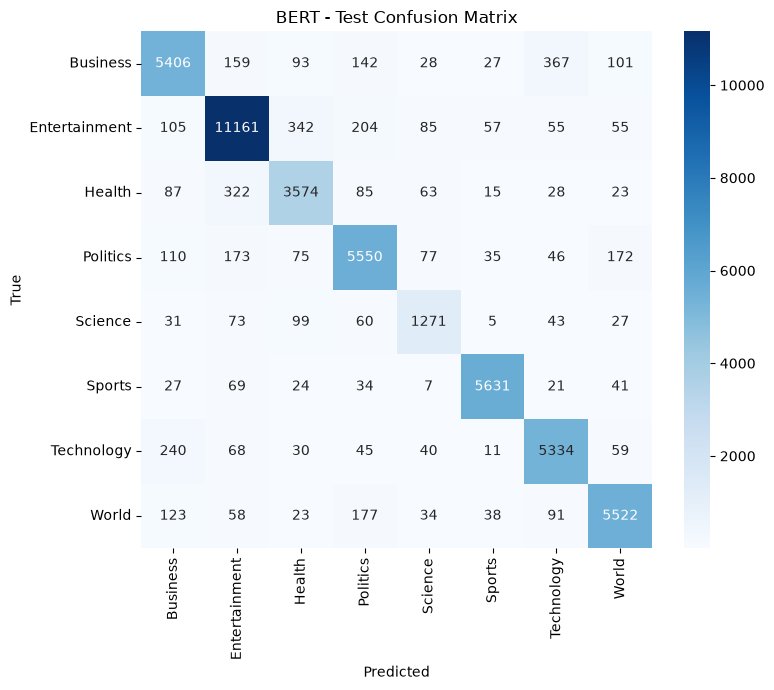

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

RESULTS_DIR = Path("../../../results/bert")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("BERT - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "BERT_a_confusion_matrix.png", dpi=150)
plt.show()

In [12]:
# load_best_model_at_end=True already restored the best (by macro_f1) checkpoint into `trainer`.
trainer.save_model(str(MODELS_DIR))
tokenizer.save_pretrained(str(MODELS_DIR))

metrics = {
    "model_family": "bert",
    "model_name": MODEL_CHECKPOINT,
    "run_timestamp": pd.Timestamp.utcnow().isoformat(),
    "label_order": LABEL_ORDER,
    "config": {
        "max_length": MAX_LENGTH,
        "batch_size": training_args.per_device_train_batch_size,
        "epochs_planned": training_args.num_train_epochs,
        "epochs_trained": trainer.state.epoch,
        "learning_rate": training_args.learning_rate,
        "use_class_weights": False,
    },
    "train": {
        "n_train": len(train_df),
        "n_val": len(val_df),
        "train_time_sec": train_time_sec,
        "epochs_trained": trainer.state.epoch,
        "history": {"log_history": trainer.state.log_history},
    },
    "test": {
        "n_test": len(test_df),
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
    },
    "environment": {
        "framework": "pytorch+transformers",
        "framework_version": torch.__version__,
        "device": "GPU" if torch.cuda.is_available() else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "BERT_a_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

for sub in MODELS_DIR.glob("checkpoint-*"):
    if sub.is_dir():
        shutil.rmtree(sub)

print("Saved:")
print(" ", MODELS_DIR)
print(" ", RESULTS_DIR / "BERT_a_metrics.json")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.29it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.28it/s]


C:\Users\oofuc\AppData\Local\Temp\ipykernel_26868\2683242660.py:8: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  "run_timestamp": pd.Timestamp.utcnow().isoformat(),


Saved:
  ..\..\weights\bert
  ..\..\..\results\bert\BERT_a_metrics.json
